# Checkpoint Three: Exploratory Analysis
**CS 418 · Socioeconomic Health Disparities · Group: Anirudh Gupta, Claudia Jimenez, Andrew Mcclendon, Auon Muhammad Naqvi, Jesus Rodriguez**

## How to use this notebook
1. Work **only inside your own section** (find it in the table below). Don't edit anyone else's.
2. Use the **dataset variable names** in the setup cell (`pop`, `air`, `income`, `emis`). Don't reuse `df`.
3. **Relative paths only** (`data/...`). No `C:/Users/...` or `/home/...`.
4. **Polars** for data handling; matplotlib/seaborn for plots. Label axes at a readable size.
5. Every plot gets a **markdown cell right below it** using the template. Every number you write must come from a code cell.
6. **AI policy:** AI may help with plotting/data-handling mechanics only. Notes, anomalies, "so what / what next" and research questions must be written by you.
7. Before committing: **Kernel → Restart & Run All** on your own copy, and make sure it runs with no errors.

## Who does what
| # | Person | Section | Steps covered |
|---|---|---|---|
| 1 | Andrew | Population dataset (primary) + Relationship plot R1 | 1, 2, 3, 4–6 |
| 2 | Claudia | Open Air dataset (primary) + Relationship plot R2 | 1, 2, 3, 4–6 |
| 3 | Ani | Income + Emissions datasets (secondary) + Relationship plot R3 | 1, 2, 3, 4–6 |
| 4 | Auon | Join: Open Air → community areas + Relationship plot R4 (**required join/comparison**) | 4–6 |
| 5 | Jesus | Relationship plot R5 + Anomaly summary table + Revised research questions | 2, 4–6 |

*(Rubric: 1 profiles · 2 anomalies · 3 distributions · 4 relationships (≥3, incl. the join) · 5 "so what" · 6 "what next")*

In [7]:
# ---- SHARED SETUP: don't edit. Run this first. ----
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

pl.Config.set_tbl_cols(-1)

pop    = pl.read_csv("data/Chicago_Community_Population_Data.csv", infer_schema_length=10000)               # primary
air    = pl.read_csv("data/Open_Air_Chicago_Day_Aggregations_sample_20260928.csv", infer_schema_length=10000) # primary
income = pl.read_csv("data/Chicago_Median_Income_By_Community_Area.csv", infer_schema_length=10000)         # secondary
emis   = pl.read_csv("data/CommunityAreas_LocalEmission2019.csv", infer_schema_length=10000)                # secondary

---
# Population dataset
**Owner: Andrew** · Primary dataset: `data/Chicago_Community_Population_Data.csv`

## Step 1 · Profile

In [8]:
print(pop.shape)
print(pop.schema)
pop.glimpse()

(77, 30)
Schema({'ACS Year': Int64, 'Community Area': String, 'Under $25,000': String, '$25,000 to $49,999': String, '$50,000 to $74,999': String, '$75,000 to $125,000': String, '$125,000 +': String, 'Male 0 to 17': String, 'Male 18 to 24': String, 'Male 25 to 34': String, 'Male 35 to 49': String, 'Male 50 to 64': String, 'Male 65+': String, 'Female 0 to 17': String, 'Female 18 to 24': String, 'Female 25 to 34': String, 'Female 35 to 49': String, 'Female 50 to 64': String, 'Female 65 +': String, 'Total Population': String, 'White': String, 'Black or African American': String, 'American Indian or Alaska Native': String, 'Asian': String, 'Native Hawaiian or Pacific Islander': Int64, 'Other Race': String, 'Multiracial': String, 'White Not Hispanic or Latino': String, 'Hispanic or Latino': String, 'Record ID': String})
Rows: 77
Columns: 30
$ ACS Year                            <i64> 2023, 2023, 2023, 2023, 2023, 2023, 2023, 2023, 2023, 2023
$ Community Area                      <str> 'ALBA

All listed race had at least one area where their population count was in the single or double digits.

In [9]:
pop.null_count()

ACS Year,Community Area,"Under $25,000","$25,000 to $49,999","$50,000 to $74,999","$75,000 to $125,000","$125,000 +",Male 0 to 17,Male 18 to 24,Male 25 to 34,Male 35 to 49,Male 50 to 64,Male 65+,Female 0 to 17,Female 18 to 24,Female 25 to 34,Female 35 to 49,Female 50 to 64,Female 65 +,Total Population,White,Black or African American,American Indian or Alaska Native,Asian,Native Hawaiian or Pacific Islander,Other Race,Multiracial,White Not Hispanic or Latino,Hispanic or Latino,Record ID
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Good data set, not missing any data

In [10]:
pop.describe()

statistic,ACS Year,Community Area,"Under $25,000","$25,000 to $49,999","$50,000 to $74,999","$75,000 to $125,000","$125,000 +",Male 0 to 17,Male 18 to 24,Male 25 to 34,Male 35 to 49,Male 50 to 64,Male 65+,Female 0 to 17,Female 18 to 24,Female 25 to 34,Female 35 to 49,Female 50 to 64,Female 65 +,Total Population,White,Black or African American,American Indian or Alaska Native,Asian,Native Hawaiian or Pacific Islander,Other Race,Multiracial,White Not Hispanic or Latino,Hispanic or Latino,Record ID
str,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,str,str,str,str,str
"""count""",77.0,"""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""","""77""",77.0,"""77""","""77""","""77""","""77""","""77"""
"""null_count""",0.0,"""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""",0.0,"""0""","""0""","""0""","""0""","""0"""
"""mean""",2023.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,17.909091,null,null,null,null,null
"""std""",0.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,34.429249,null,null,null,null,null
"""min""",2023.0,"""ALBANY PARK""","""1,007""","""1,022""","""1,002""","""1,019""","""1,030""","""1,099""","""1,042""","""1,052""","""1,005""","""1,057""","""1,010""","""1,022""","""1,018""","""1,027""","""1,056""","""1,001""","""1,021""","""100,278""","""1,123""","""1,079""","""0""","""0""",0.0,"""0""","""1,015""","""1,066""","""1,114""","""2023_ALBANY PARK"""
"""25%""",2023.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,null,null
"""50%""",2023.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0.0,null,null,null,null,null
"""75%""",2023.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,21.0,null,null,null,null,null
"""max""",2023.0,"""WOODLAWN""","""965""","""997""","""974""","""979""","""988""","""930""","""940""","""933""","""9,920""","""8,110""","""853""","""9,697""","""978""","""978""","""9,695""","""999""","""909""","""91,635""","""908""","""991""","""993""","""991""",171.0,"""993""","""936""","""995""","""981""","""2023_WOODLAWN"""


Not as informative because the min and max dont tell me which area its from

## Step 2 · Anomalies
Check for: missing values, duplicates, inconsistent formatting, wrong data types, invalid values, mixed units.

| Anomaly | Column(s) | Rows affected | What we did (fixed / dropped / flagged) |
|---|---|---|---|
| N/A | N/A  | N/A   | N/A  |

## Step 3 · Distributions
One plot per feature that matters to the research questions.

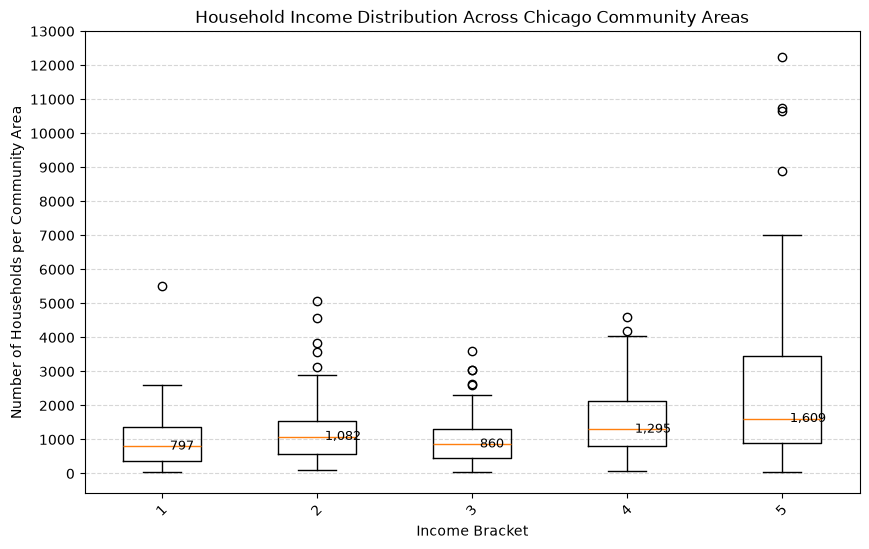

In [20]:
import polars as pl
import matplotlib.pyplot as plt

income_cols = [
    'Under $25,000',
    '$25,000 to $49,999',
    '$50,000 to $74,999',
    '$75,000 to $125,000',
    '$125,000 +'
]

income_labels = [
    'Under $25,000',
    '$25,000 - $49,999',
    '$50,000 - $74,999',
    '$75,000 - $125,000',
    '$125,000+'
]

for col in income_cols:
    if pop.schema[col] == pl.String:
        pop = pop.with_columns(
            pl.col(col)
            .str.replace_all(",", "")
            .cast(pl.Int64)
        )

data = [
    pop[col].drop_nulls().to_list()
    for col in income_cols
]

plt.figure(figsize=(10, 6))

plt.boxplot(
    data,
    label=income_labels
)

medians = [
    pop[col].median()
    for col in income_cols
]

for i, median in enumerate(medians, start=1):
    plt.text(
        i + 0.05,
        median,
        f'{median:,.0f}',
        verticalalignment='center',
        fontsize=9
    )

plt.title("Household Income Distribution Across Chicago Community Areas")
plt.xlabel("Income Bracket")
plt.ylabel("Number of Households per Community Area")

plt.yticks(range(0, 13001, 1000))

plt.grid(
    axis='y',
    linestyle='--',
    alpha=0.5
)

plt.xticks(rotation=45)


plt.show()

**Distribution 1: [feature name]**
- **Center:** The median househould dont get above 2000 but stil vary but hovers between about 800 and 1600
- **Spread:** 125,000 has the gratest variability and lonest whiskers and the under 250000 have smaller spreads. It seems wealthier income communites tend to group 
- **Skew / shape:** all brackets are right skewed
- **Outliers:** every category has outliers on the increasing side


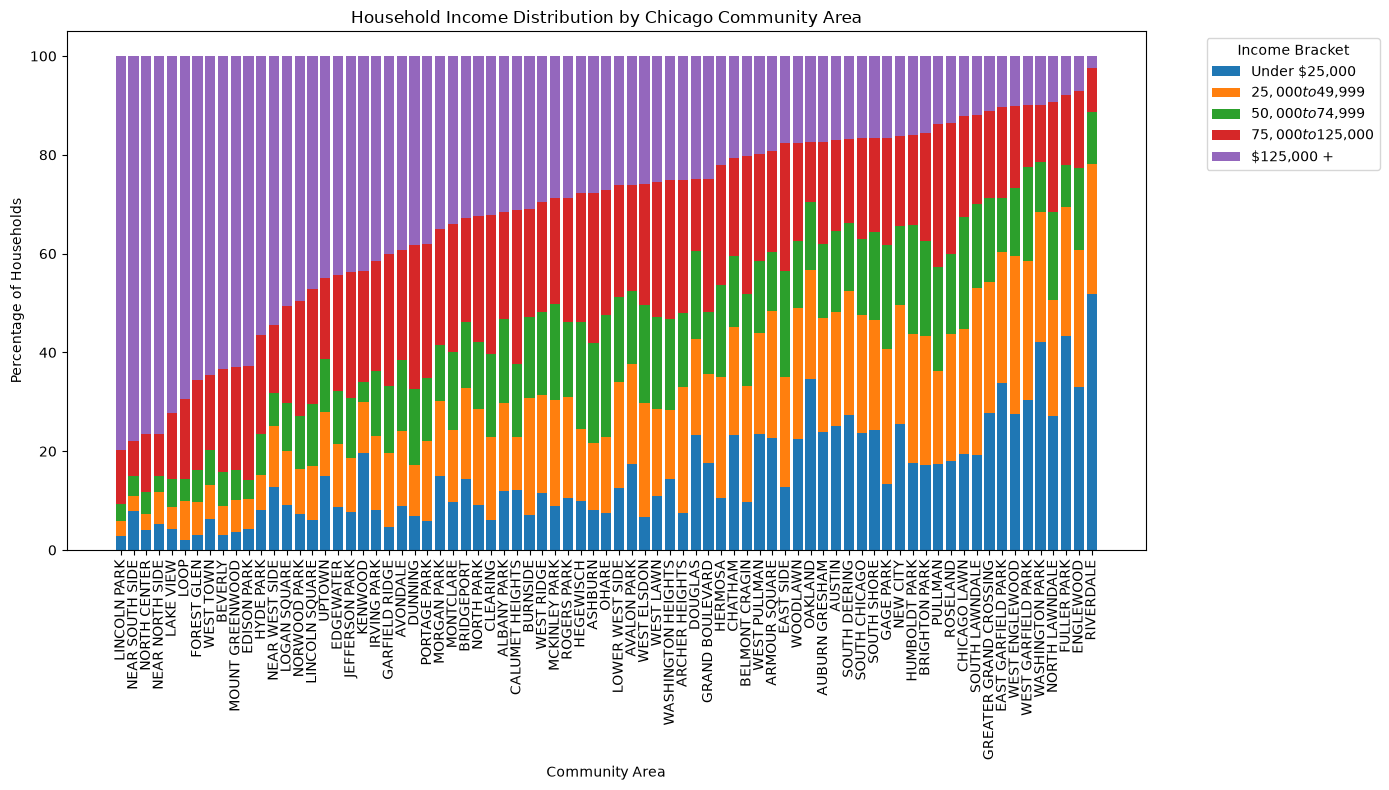

In [22]:


income_cols = [
    'Under $25,000',
    '$25,000 to $49,999',
    '$50,000 to $74,999',
    '$75,000 to $125,000',
    '$125,000 +'
]

income_labels = [
    'Under $25,000',
    '$25,000 - $49,999',
    '$50,000 - $74,999',
    '$75,000 - $125,000',
    '$125,000+'
]



for col in income_cols:
    if pop.schema[col] == pl.String:
        pop = pop.with_columns(
            pl.col(col)
            .str.replace_all(",", "")
            .cast(pl.Int64)
        )


neighborhood_col = "Community Area"


pop = pop.with_columns(
    pl.sum_horizontal(income_cols).alias("Total Households")
)


for col in income_cols:
    pop = pop.with_columns(
        (pl.col(col) / pl.col("Total Households") * 100)
        .alias(col + " %")
    )


pop = pop.sort("$125,000 + %", descending=True)

neighborhoods = pop[neighborhood_col].to_list()

plt.figure(figsize=(14, 8))

bottom = [0] * len(neighborhoods)

for col in income_cols:
    values = pop[col + " %"].to_list()

    plt.bar(
        neighborhoods,
        values,
        bottom=bottom,
        label=col
    )

    bottom = [
        bottom[i] + values[i]
        for i in range(len(values))
    ]

plt.title("Household Income Distribution by Chicago Community Area")
plt.xlabel("Community Area")
plt.ylabel("Percentage of Households")

plt.xticks(rotation=90)

plt.legend(title="Income Bracket", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()

---
# Open Air Chicago dataset
**Owner: Claudia** · Primary dataset: `data/Open_Air_Chicago_Day_Aggregations_sample_...csv`

## Step 1 · Profile

In [ ]:
print(air.shape)
print(air.schema)
air.glimpse()

In [ ]:
air.null_count()

In [ ]:
air.describe()

**What stands out:** *(your notes — only things you can point to in the outputs above)*

-

## Step 2 · Anomalies
Check for: missing values, duplicates, inconsistent formatting, wrong data types, invalid values, mixed units.

| Anomaly | Column(s) | Rows affected | What we did (fixed / dropped / flagged) |
|---|---|---|---|
|  |  |  |  |

In [ ]:
# Code that finds each anomaly (e.g. duplicate count, bad values). Rows affected must come from here.

## Step 3 · Distributions
One plot per feature that matters to the research questions.

In [ ]:
# Distribution plot 1: histogram / box plot / bar chart. Label axes.
fig, ax = plt.subplots(figsize=(7, 4))
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("")
plt.show()

**Distribution 1: [feature name]**
- **Center:** 
- **Spread:** 
- **Skew / shape:** 
- **Outliers:**

In [ ]:
# Distribution plot 2: histogram / box plot / bar chart. Label axes.
fig, ax = plt.subplots(figsize=(7, 4))
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("")
plt.show()

**Distribution 2: [feature name]**
- **Center:** 
- **Spread:** 
- **Skew / shape:** 
- **Outliers:**

*(Add more distribution plots + notes if more features matter.)*

---
# Join: Open Air sensors → community areas
**Owner: Auon**

The Open Air data is per *sensor*, not per community area. To compare it with income, each sensor needs a community area.
Document how you did it and how many sensors/rows you could or couldn't match.

In [ ]:
# Join code here. Print match counts (matched / unmatched sensors) so they're traceable.

**Join notes:** *(method, rows matched, rows unmatched, what you did with unmatched)*

-

---
# Community Area Local Emission dataset
**Owner: Auon** · Primary dataset: `data/CommunityArea_...csv`

## Step 1 · Profile

In [23]:
print(emis.shape)
print(emis.schema)
emis.glimpse()

(77, 67)
Schema({'OBJECTID': Int64, 'COMMUNITY': String, 'CCA_TXT': Int64, 'CCA_NUM': Int64, 'ID': Int64, 'ID_1': Int64, 'GEO': String, 'TYPE': String, 'COUNTY': String, 'AREA': Int64, 'POP': Int64, 'JOBS': Float64, 'INCOME': Int64, 'HOUSEHOLDS': Int64, 'SF_HU': Float64, 'OCC_OWN': Float64, 'TREE_COV': Float64, 'IMP_SUR': Float64, 'GRC_MEM': String, 'RES_ELE_CO': Int64, 'NONRES_ELE': Int64, 'RES_NG_CO2': Float64, 'NONRES_NG_': Float64, 'ONROAD_CO2': Int64, 'ONROAD_COM': Int64, 'ONROAD_PAS': Int64, 'ONROAD_PUB': Float64, 'WASTE_CO2E': Int64, 'RES_ELE__1': Float64, 'NONRES_E_1': Float64, 'RES_NG_C_1': Float64, 'NONRES_NG1': Float64, 'ONROAD_C_1': Float64, 'WASTE_CO_1': Float64, 'EV_COUNT': Float64, 'EV_PERCENT': Float64, 'EV_STA_L2': String, 'EV_STA_DCF': String, 'EV_STA_TOT': String, 'WALKABILIY': Float64, 'TRAN_AVAIL': Float64, 'MODE_DRIVE': Float64, 'MODE_POOL': Float64, 'MODE_TRANS': Float64, 'MODE_WALK_': Float64, 'MODE_OTHER': Float64, 'RES_VMT': Float64, 'HH_VEHICLE': Float64, 'RE

In [24]:
emis.null_count()

OBJECTID,COMMUNITY,CCA_TXT,CCA_NUM,ID,ID_1,GEO,TYPE,COUNTY,AREA,POP,JOBS,INCOME,HOUSEHOLDS,SF_HU,OCC_OWN,TREE_COV,IMP_SUR,GRC_MEM,RES_ELE_CO,NONRES_ELE,RES_NG_CO2,NONRES_NG_,ONROAD_CO2,ONROAD_COM,ONROAD_PAS,ONROAD_PUB,WASTE_CO2E,RES_ELE__1,NONRES_E_1,RES_NG_C_1,NONRES_NG1,ONROAD_C_1,WASTE_CO_1,EV_COUNT,EV_PERCENT,EV_STA_L2,EV_STA_DCF,EV_STA_TOT,WALKABILIY,TRAN_AVAIL,MODE_DRIVE,MODE_POOL,MODE_TRANS,MODE_WALK_,MODE_OTHER,RES_VMT,HH_VEHICLE,RES_ELE_KW,NONRES_E_2,RES_NG_BTU,NONRES_N_1,RES_ELE__2,NONRES_E_3,RES_NG_B_1,NONRES_N_2,RES_ELE__3,RES_NG_B_2,SOLAR_POT,SOLSMART,Acres,Square_met,Sq_mi,Sq_ft,ft,Shape__Area,Shape__Length
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [25]:
emis.describe()

statistic,OBJECTID,COMMUNITY,CCA_TXT,CCA_NUM,ID,ID_1,GEO,TYPE,COUNTY,AREA,POP,JOBS,INCOME,HOUSEHOLDS,SF_HU,OCC_OWN,TREE_COV,IMP_SUR,GRC_MEM,RES_ELE_CO,NONRES_ELE,RES_NG_CO2,NONRES_NG_,ONROAD_CO2,ONROAD_COM,ONROAD_PAS,ONROAD_PUB,WASTE_CO2E,RES_ELE__1,NONRES_E_1,RES_NG_C_1,NONRES_NG1,ONROAD_C_1,WASTE_CO_1,EV_COUNT,EV_PERCENT,EV_STA_L2,EV_STA_DCF,EV_STA_TOT,WALKABILIY,TRAN_AVAIL,MODE_DRIVE,MODE_POOL,MODE_TRANS,MODE_WALK_,MODE_OTHER,RES_VMT,HH_VEHICLE,RES_ELE_KW,NONRES_E_2,RES_NG_BTU,NONRES_N_1,RES_ELE__2,NONRES_E_3,RES_NG_B_1,NONRES_N_2,RES_ELE__3,RES_NG_B_2,SOLAR_POT,SOLSMART,Acres,Square_met,Sq_mi,Sq_ft,ft,Shape__Area,Shape__Length
str,f64,str,f64,f64,f64,f64,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,f64,f64,f64,f64,f64,f64,f64
"""count""",77.0,"""77""",77.0,77.0,77.0,77.0,"""77""","""77""","""77""",77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,"""77""",77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,"""77""","""77""","""77""",77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,"""77""","""77""",77.0,77.0,77.0,77.0,77.0,77.0,77.0
"""null_count""",0.0,"""0""",0.0,0.0,0.0,0.0,"""0""","""0""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""0""","""0""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""0""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",39.0,null,39.0,39.0,39.0,39.0,null,null,null,1918.675325,35667.376623,17058.376623,56199.935065,14840.584416,0.388701,0.477013,0.203896,0.683896,null,32010.74026,81611.454545,52842.155844,70227.25974,111441.545455,34579.194805,75666.831169,1195.532468,13110.753247,0.870909,2.118831,1.48,1.97,3.762208,0.37,40.402597,0.000779,null,null,null,0.973506,0.995065,0.562727,0.087792,0.26961,0.063896,0.015974,11651.844156,1.233377,8.2283e7,2.0978e8,994872.623377,1.3222e6,2238.506494,5444.805195,28.0,37.0,5611.675325,71.467532,null,null,110.859807,448633.720953,0.0,4.8290e6,2254.882918,1.4005e7,18171.098126
"""std""",22.371857,null,22.371857,22.371857,22.371857,22.371857,null,null,null,1261.796927,23675.47301,55488.711289,27028.194034,12009.835562,0.260341,0.194443,0.066157,0.104455,null,25537.457151,168943.697621,35075.852998,46615.757428,128429.41852,34800.151714,106291.232798,789.371479,8702.683339,0.191168,3.176218,2.2350e-16,2.2350e-16,5.276111,5.5875e-17,73.032664,0.002698,null,null,null,0.101226,0.030976,0.138018,0.039324,0.109586,0.082113,0.011269,3447.44413,0.405812,6.5643e7,4.3427e8,660381.577163,877647.637337,490.518271,8164.848884,0.0,0.0,1144.039191,13.336322,null,null,972.790856,3.9367e6,0.0,4.2375e7,19786.5173,9.2078e6,8235.420959
"""min""",1.0,"""ALBANY PARK""",1.0,1.0,1.0,1.0,"""Albany Park""","""Chicago Community Area""","""Cook""",372.0,2527.0,161.0,15396.0,1036.0,0.04,0.07,0.08,0.36,""" NA""",685.0,993.0,3744.0,4976.0,8842.0,2122.0,5728.0,180.0,929.0,0.09,0.14,1.48,1.97,1.19,0.37,0.0,0.0,""" -""",""" -""",""" -""",0.25,0.74,0.24,0.02,0.08,0.0,0.0,5747.0,0.46,1.760956e6,2.552379e6,70486.0,93676.0,242.0,351.0,28.0,37.0,698.0,44.0,""" -""","""NA""",0.0,0.0,0.0,0.0,0.0,2.8317e6,7412.072569
"""25%""",20.0,null,20.0,20.0,20.0,20.0,null,null,null,1141.0,18628.0,2540.0,34396.0,6850.0,0.15,0.36,0.16,0.63,null,16607.0,21857.0,27598.0,36678.0,49253.0,13516.0,30998.0,619.0,6847.0,0.73,0.87,1.48,1.97,1.8,0.37,6.0,0.0,null,null,null,1.0,1.0,0.48,0.06,0.18,0.02,0.01,8466.0,0.9,4.2688773e7,5.6181643e7,519592.0,690538.0,1876.0,2247.0,28.0,37.0,4943.0,62.0,null,null,0.0,0.0,0.0,0.0,0.0,8.3409e6,13088.284372
"""50%""",39.0,null,39.0,39.0,39.0,39.0,null,null,null,1828.0,29647.0,5144.0,51689.0,11278.0,0.31,0.45,0.2,0.69,null,24526.0,40192.0,43923.0,58373.0,74098.0,21797.0,45075.0,1076.0,10898.0,0.89,1.05,1.48,1.97,2.22,0.37,13.0,0.0,nul

**What stands out:** *(your notes — only things you can point to in the outputs above)*

-

## Step 2 · Anomalies
Check for: missing values, duplicates, inconsistent formatting, wrong data types, invalid values, mixed units.

| Anomaly | Column(s) | Rows affected | What we did (fixed / dropped / flagged) |
|---|---|---|---|
|  |  |  |  |

In [ ]:
# Code that finds each anomaly (e.g. duplicate count, bad values). Rows affected must come from here.

## Step 3 · Distributions
One plot per feature that matters to the research questions.

In [ ]:
# Distribution plot 1: histogram / box plot / bar chart. Label axes.
fig, ax = plt.subplots(figsize=(7, 4))
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("")
plt.show()

**Distribution 1: [feature name]**
- **Center:** 
- **Spread:** 
- **Skew / shape:** 
- **Outliers:**

In [ ]:
# Distribution plot 2: histogram / box plot / bar chart. Label axes.
fig, ax = plt.subplots(figsize=(7, 4))
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("")
plt.show()

**Distribution 2: [feature name]**
- **Center:** 
- **Spread:** 
- **Skew / shape:** 
- **Outliers:**

*(Add more distribution plots + notes if more features matter.)*

In [ ]:
# R4: scatter / subgroup comparison / time series / correlation matrix. Label axes at a readable size.
# Watch for overplotting and remember: correlation != causation.
fig, ax = plt.subplots(figsize=(7, 5))
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("")
plt.show()

---
# Income dataset
**Owner: Jesus** · Secondary dataset: `data/Chicago_Median_Income_By_Community_Area.csv`

In [26]:
print(income.shape)
print(income.schema)
income.glimpse()

(78, 5)
Schema({'Layer': String, 'Name': String, 'GEOID': Int64, 'INC_2020-2024': String, 'PCI_2020-2024': String})
Rows: 78
Columns: 5
$ Layer         <str> null, 'Community area', 'Community area', 'Community area', 'Community area', 'Community area', 'Community area', 'Community area', 'Community area', 'Community area'
$ Name          <str> null, 'Rogers Park', 'Norwood Park', 'Jefferson Park', 'Forest Glen', 'North Park', 'Albany Park', 'Portage Park', 'Irving Park', 'Dunning'
$ GEOID         <i64> null, 1, 10, 11, 12, 13, 14, 15, 16, 17
$ INC_2020-2024 <str> 'Median household income, 2020-2024', '64982.84252006701', '117196.55685334843', '99973.6803472109', '143029.53249393537', '70550.56287265262', '89407.95574996143', '94793.33527687968', '95607.64589337097', '90515.97830108434'
$ PCI_2020-2024 <str> 'Per capita income, 2020-2024', '41401.316073557224', '53787.75290118216', '51002.44814039693', '72837.37767535771', '39578.42721913615', '44491.796264110155', '44349.38581261013',

In [ ]:
income.null_count()

OBJECTID,COMMUNITY,CCA_TXT,CCA_NUM,ID,ID_1,GEO,TYPE,COUNTY,AREA,POP,JOBS,INCOME,HOUSEHOLDS,SF_HU,OCC_OWN,TREE_COV,IMP_SUR,GRC_MEM,RES_ELE_CO,NONRES_ELE,RES_NG_CO2,NONRES_NG_,ONROAD_CO2,ONROAD_COM,ONROAD_PAS,ONROAD_PUB,WASTE_CO2E,RES_ELE__1,NONRES_E_1,RES_NG_C_1,NONRES_NG1,ONROAD_C_1,WASTE_CO_1,EV_COUNT,EV_PERCENT,EV_STA_L2,EV_STA_DCF,EV_STA_TOT,WALKABILIY,TRAN_AVAIL,MODE_DRIVE,MODE_POOL,MODE_TRANS,MODE_WALK_,MODE_OTHER,RES_VMT,HH_VEHICLE,RES_ELE_KW,NONRES_E_2,RES_NG_BTU,NONRES_N_1,RES_ELE__2,NONRES_E_3,RES_NG_B_1,NONRES_N_2,RES_ELE__3,RES_NG_B_2,SOLAR_POT,SOLSMART,Acres,Square_met,Sq_mi,Sq_ft,ft,Shape__Area,Shape__Length
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [ ]:
income.describe()

statistic,OBJECTID,COMMUNITY,CCA_TXT,CCA_NUM,ID,ID_1,GEO,TYPE,COUNTY,AREA,POP,JOBS,INCOME,HOUSEHOLDS,SF_HU,OCC_OWN,TREE_COV,IMP_SUR,GRC_MEM,RES_ELE_CO,NONRES_ELE,RES_NG_CO2,NONRES_NG_,ONROAD_CO2,ONROAD_COM,ONROAD_PAS,ONROAD_PUB,WASTE_CO2E,RES_ELE__1,NONRES_E_1,RES_NG_C_1,NONRES_NG1,ONROAD_C_1,WASTE_CO_1,EV_COUNT,EV_PERCENT,EV_STA_L2,EV_STA_DCF,EV_STA_TOT,WALKABILIY,TRAN_AVAIL,MODE_DRIVE,MODE_POOL,MODE_TRANS,MODE_WALK_,MODE_OTHER,RES_VMT,HH_VEHICLE,RES_ELE_KW,NONRES_E_2,RES_NG_BTU,NONRES_N_1,RES_ELE__2,NONRES_E_3,RES_NG_B_1,NONRES_N_2,RES_ELE__3,RES_NG_B_2,SOLAR_POT,SOLSMART,Acres,Square_met,Sq_mi,Sq_ft,ft,Shape__Area,Shape__Length
str,f64,str,f64,f64,f64,f64,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,f64,f64,f64,f64,f64,f64,f64
"""count""",77.0,"""77""",77.0,77.0,77.0,77.0,"""77""","""77""","""77""",77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,"""77""",77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,"""77""","""77""","""77""",77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,77.0,"""77""","""77""",77.0,77.0,77.0,77.0,77.0,77.0,77.0
"""null_count""",0.0,"""0""",0.0,0.0,0.0,0.0,"""0""","""0""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""0""","""0""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""0""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",39.0,null,39.0,39.0,39.0,39.0,null,null,null,1918.675325,35667.376623,17058.376623,56199.935065,14840.584416,0.388701,0.477013,0.203896,0.683896,null,32010.74026,81611.454545,52842.155844,70227.25974,111441.545455,34579.194805,75666.831169,1195.532468,13110.753247,0.870909,2.118831,1.48,1.97,3.762208,0.37,40.402597,0.000779,null,null,null,0.973506,0.995065,0.562727,0.087792,0.26961,0.063896,0.015974,11651.844156,1.233377,8.2283e7,2.0978e8,994872.623377,1.3222e6,2238.506494,5444.805195,28.0,37.0,5611.675325,71.467532,null,null,110.859807,448633.720953,0.0,4.8290e6,2254.882918,1.4005e7,18171.098126
"""std""",22.371857,null,22.371857,22.371857,22.371857,22.371857,null,null,null,1261.796927,23675.47301,55488.711289,27028.194034,12009.835562,0.260341,0.194443,0.066157,0.104455,null,25537.457151,168943.697621,35075.852998,46615.757428,128429.41852,34800.151714,106291.232798,789.371479,8702.683339,0.191168,3.176218,2.2350e-16,2.2350e-16,5.276111,5.5875e-17,73.032664,0.002698,null,null,null,0.101226,0.030976,0.138018,0.039324,0.109586,0.082113,0.011269,3447.44413,0.405812,6.5643e7,4.3427e8,660381.577163,877647.637337,490.518271,8164.848884,0.0,0.0,1144.039191,13.336322,null,null,972.790856,3.9367e6,0.0,4.2375e7,19786.5173,9.2078e6,8235.420959
"""min""",1.0,"""ALBANY PARK""",1.0,1.0,1.0,1.0,"""Albany Park""","""Chicago Community Area""","""Cook""",372.0,2527.0,161.0,15396.0,1036.0,0.04,0.07,0.08,0.36,""" NA""",685.0,993.0,3744.0,4976.0,8842.0,2122.0,5728.0,180.0,929.0,0.09,0.14,1.48,1.97,1.19,0.37,0.0,0.0,""" -""",""" -""",""" -""",0.25,0.74,0.24,0.02,0.08,0.0,0.0,5747.0,0.46,1.760956e6,2.552379e6,70486.0,93676.0,242.0,351.0,28.0,37.0,698.0,44.0,""" -""","""NA""",0.0,0.0,0.0,0.0,0.0,2.8317e6,7412.072569
"""25%""",20.0,null,20.0,20.0,20.0,20.0,null,null,null,1141.0,18628.0,2540.0,34396.0,6850.0,0.15,0.36,0.16,0.63,null,16607.0,21857.0,27598.0,36678.0,49253.0,13516.0,30998.0,619.0,6847.0,0.73,0.87,1.48,1.97,1.8,0.37,6.0,0.0,null,null,null,1.0,1.0,0.48,0.06,0.18,0.02,0.01,8466.0,0.9,4.2688773e7,5.6181643e7,519592.0,690538.0,1876.0,2247.0,28.0,37.0,4943.0,62.0,null,null,0.0,0.0,0.0,0.0,0.0,8.3409e6,13088.284372
"""50%""",39.0,null,39.0,39.0,39.0,39.0,null,null,null,1828.0,29647.0,5144.0,51689.0,11278.0,0.31,0.45,0.2,0.69,null,24526.0,40192.0,43923.0,58373.0,74098.0,21797.0,45075.0,1076.0,10898.0,0.89,1.05,1.48,1.97,2.22,0.37,13.0,0.0,nul

**What stands out:** *(your notes — only things you can point to in the outputs above)*

-

## Step 2 · Anomalies
Check for: missing values, duplicates, inconsistent formatting, wrong data types, invalid values, mixed units.

| Anomaly | Column(s) | Rows affected | What we did (fixed / dropped / flagged) |
|---|---|---|---|
|  |  |  |  |

In [ ]:
# Code that finds each anomaly (e.g. duplicate count, bad values). Rows affected must come from here.

## Step 3 · Distributions
One plot per feature that matters to the research questions.

In [ ]:
# Distribution plot 1: histogram / box plot / bar chart. Label axes.
fig, ax = plt.subplots(figsize=(7, 4))
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("")
plt.show()

**Distribution 1: [feature name]**
- **Center:** 
- **Spread:** 
- **Skew / shape:** 
- **Outliers:**

In [ ]:
# Distribution plot 2: histogram / box plot / bar chart. Label axes.
fig, ax = plt.subplots(figsize=(7, 4))
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("")
plt.show()

**Distribution 2: [feature name]**
- **Center:** 
- **Spread:** 
- **Skew / shape:** 
- **Outliers:**

*(Add more distribution plots + notes if more features matter.)*

---
# Step 4 · Relationships
**Owner: Ani** · *Join `income` and `emis` on community area name (see `Ani_Data.ipynb`).*


In [ ]:
# R3: scatter / subgroup comparison / time series / correlation matrix. Label axes at a readable size.
# Watch for overplotting and remember: correlation != causation.
fig, ax = plt.subplots(figsize=(7, 5))
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("")
plt.show()

In [ ]:
# R3: scatter / subgroup comparison / time series / correlation matrix. Label axes at a readable size.
# Watch for overplotting and remember: correlation != causation.
fig, ax = plt.subplots(figsize=(7, 5))
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("")
plt.show()

In [ ]:
# R3: scatter / subgroup comparison / time series / correlation matrix. Label axes at a readable size.
# Watch for overplotting and remember: correlation != causation.
fig, ax = plt.subplots(figsize=(7, 5))
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("")
plt.show()

### R3: So what? (Step 5)
- **What it shows:** 
- **Why it matters for our research questions:** 
- **Did we expect this? (expected / unexpected / in between):** 

### R3: What next? (Step 6)
- **Next question this points to** *(extra comparison, subgroup to split out, dataset to join, expert to ask)*: